# About Dataset
This data set contains 13 clinicopathologic features aiming to predict recurrence of well differentiated thyroid cancer. The data set was collected in duration of 15 years and each patient was followed for at least 10 years.


`Age`: The age of the patient at the time of diagnosis or treatment.

`Gender`: The gender of the patient (male or female).

`Smoking`: Whether the patient is a smoker or not.

`Hx Smoking`: Smoking history of the patient (e.g., whether they have ever smoked).

`Hx Radiotherapy`: History of radiotherapy treatment for any condition.

`Thyroid Function`: The status of thyroid function, possibly indicating if there are any abnormalities.

`Physical Examination`: Findings from a physical examination of the patient, which may include palpation of the thyroid gland and surrounding structures.

`Adenopathy`: Presence or absence of enlarged lymph nodes (adenopathy) in the neck region.

`Pathology`: Specific types of thyroid cancer as determined by pathology examination of biopsy samples.

`Focality`: Whether the cancer is unifocal (limited to one location) or multifocal (present in multiple locations).

`Risk`: The risk category of the cancer based on various factors, such as tumor size, extent of spread, and histological type.

`T`: Tumor classification based on its size and extent of invasion into nearby structures.

`N`: Nodal classification indicating the involvement of lymph nodes.

`M`: Metastasis classification indicating the presence or absence of distant metastases.

`Stage`: The overall stage of the cancer, typically determined by combining T, N, and M classifications.

`Response`: Response to treatment, indicating whether the cancer responded positively, negatively, or remained stable after treatment.

`Recurred`: Indicates whether the cancer has recurred after initial treatment.

# Importing Libraries

In [2185]:
# Data manipulation and numerical operations
import pandas as pd   # For data manipulation and analysis
import numpy as np    # For numerical operations

import shap  # package used to calculate Shap values

# Data visualization libraries
import matplotlib.pyplot as plt   # For plotting and visualizations
import graphviz   # For visualizing decision trees
import seaborn as sns

# Scikit-learn: Model selection and evaluation
from sklearn.model_selection import train_test_split   # For splitting the data into training and testing sets
from sklearn.metrics import accuracy_score, classification_report  # For evaluating model performance
from sklearn.metrics import roc_curve, roc_auc_score  # For calculating ROC curve and AUC
from sklearn.metrics import confusion_matrix

# Scikit-learn: Preprocessing
from sklearn.preprocessing import LabelEncoder   # For encoding categorical labels into numeric values
from sklearn.preprocessing import OneHotEncoder  # For encoding categorical features using one-hot encoding

# Scikit-learn: Machine learning model
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# Scikit-learn: Tree visualization
from sklearn.tree import export_graphviz  # For exporting decision trees in DOT format
from sklearn.tree import plot_tree  # For plotting decision trees

from scipy import stats

plt.style.use('fivethirtyeight')
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

# 1. Process the Data with All Features

## 1.1 Loading the Data into a Pandas DataFrame

In [2186]:
# Specify the file path to the CSV file containing the thyroid cancer recurrence data
csv_path = "../data/thyroid_diff.csv"

# Read the CSV file into a DataFrame using pandas
df = pd.read_csv(csv_path)

# Display the first few rows of the DataFrame to get a quick overview of the data
df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
3,62,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
4,62,F,No,No,No,Euthyroid,Multinodular goiter,No,Micropapillary,Multi-Focal,Low,T1a,N0,M0,I,Excellent,No


# Check Data Shape and Quality

In [2187]:
#shape of the data
df.shape

(383, 17)

In [2188]:
#statistical information about the data
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,383.0,40.866841,15.134494,15.0,29.0,37.0,51.0,82.0


In [2189]:
#number of nulls in each column
df.isnull().sum()

Age                     0
Gender                  0
Smoking                 0
Hx Smoking              0
Hx Radiotherapy         0
Thyroid Function        0
Physical Examination    0
Adenopathy              0
Pathology               0
Focality                0
Risk                    0
T                       0
N                       0
M                       0
Stage                   0
Response                0
Recurred                0
dtype: int64

In [2190]:
#information about the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Age                   383 non-null    int64 
 1   Gender                383 non-null    object
 2   Smoking               383 non-null    object
 3   Hx Smoking            383 non-null    object
 4   Hx Radiotherapy       383 non-null    object
 5   Thyroid Function      383 non-null    object
 6   Physical Examination  383 non-null    object
 7   Adenopathy            383 non-null    object
 8   Pathology             383 non-null    object
 9   Focality              383 non-null    object
 10  Risk                  383 non-null    object
 11  T                     383 non-null    object
 12  N                     383 non-null    object
 13  M                     383 non-null    object
 14  Stage                 383 non-null    object
 15  Response              383 non-null    ob

In [2191]:
#unique values in each column
for column in df.columns:
    unique_values = df[column].unique()
    print(f"Unique values in column '{column}':")
    print(unique_values)
    print()

Unique values in column 'Age':
[27 34 30 62 52 41 46 51 40 75 59 49 50 76 42 44 43 36 70 60 33 26 37 55
 31 45 20 38 29 25 21 23 24 35 54 22 69 28 17 73 18 39 57 66 32 47 56 63
 19 67 72 61 68 48 81 53 58 80 79 65 15 82 71 64 78]

Unique values in column 'Gender':
['F' 'M']

Unique values in column 'Smoking':
['No' 'Yes']

Unique values in column 'Hx Smoking':
['No' 'Yes']

Unique values in column 'Hx Radiotherapy':
['No' 'Yes']

Unique values in column 'Thyroid Function':
['Euthyroid' 'Clinical Hyperthyroidism' 'Clinical Hypothyroidism'
 'Subclinical Hyperthyroidism' 'Subclinical Hypothyroidism']

Unique values in column 'Physical Examination':
['Single nodular goiter-left' 'Multinodular goiter'
 'Single nodular goiter-right' 'Normal' 'Diffuse goiter']

Unique values in column 'Adenopathy':
['No' 'Right' 'Extensive' 'Left' 'Bilateral' 'Posterior']

Unique values in column 'Pathology':
['Micropapillary' 'Papillary' 'Follicular' 'Hurthle cell']

Unique values in column 'Focality':
['Uni

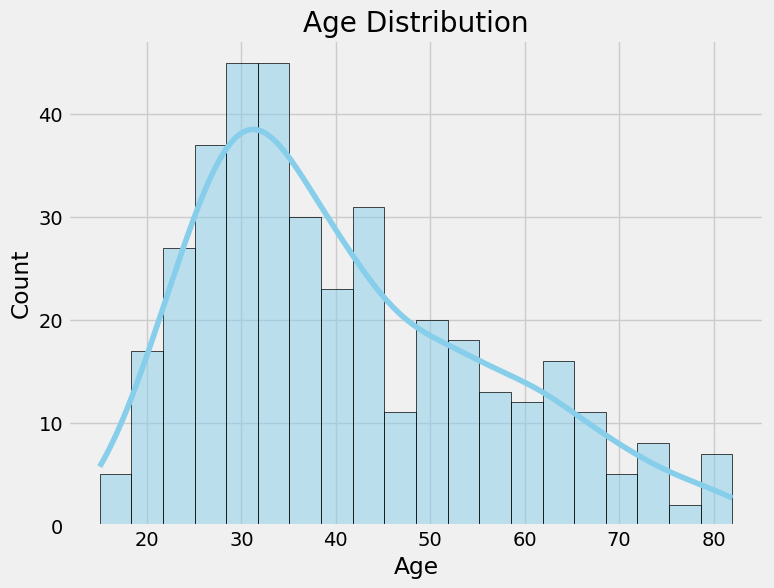

In [2192]:
#Age distribution
plt.figure(figsize = (8, 6))
sns.histplot(df['Age'], bins = 20, kde = True, color = 'skyblue', edgecolor = 'black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

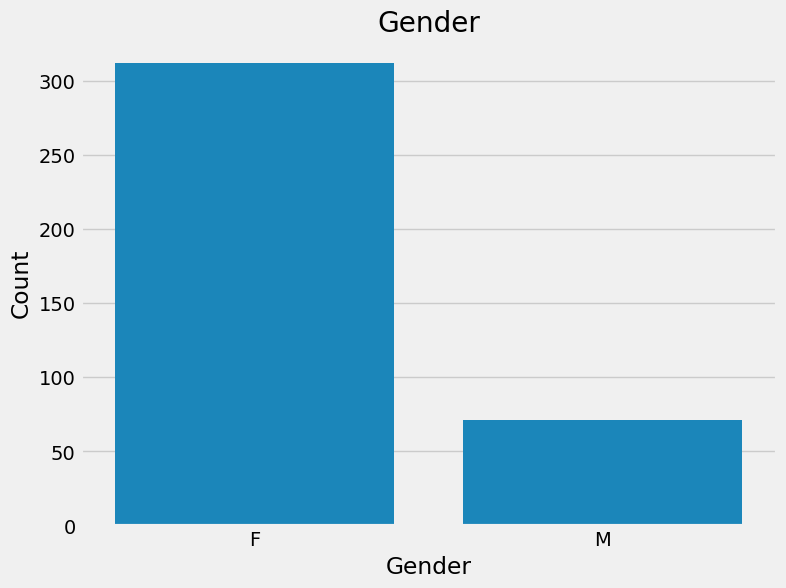

In [2193]:
#Gender
plt.figure(figsize = (8, 6))
sns.countplot(x = 'Gender', data = df)
plt.title('Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

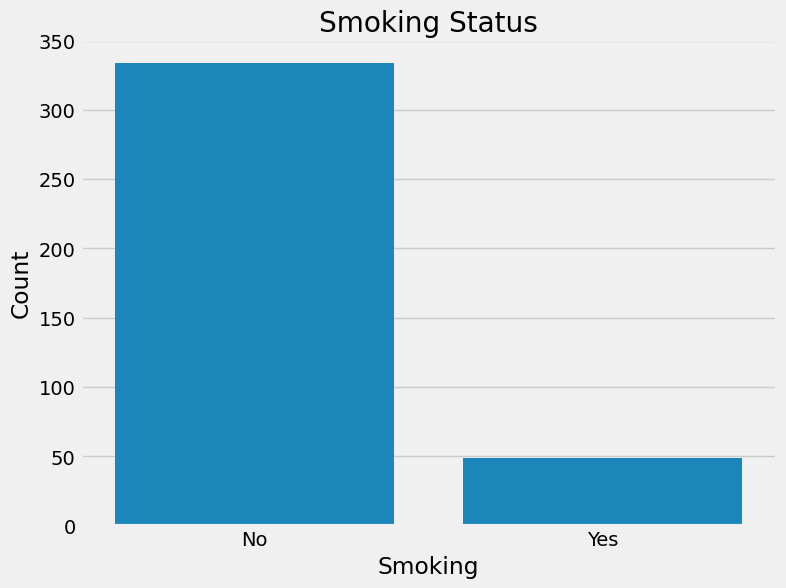

In [2194]:
#Smoking status
plt.figure(figsize = (8, 6))
sns.countplot(x = 'Smoking', data = df)
plt.title('Smoking Status')
plt.xlabel('Smoking')
plt.ylabel('Count')
plt.show()

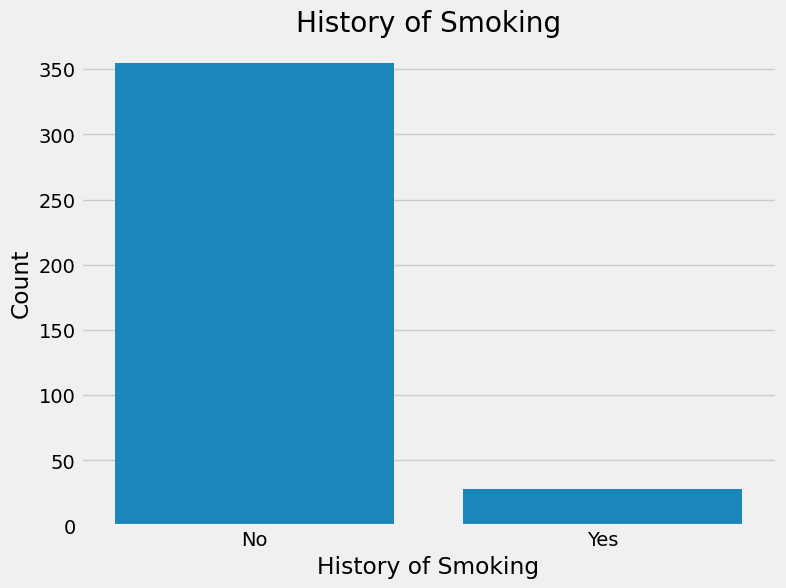

In [2195]:
#History of Smoking
plt.figure(figsize = (8, 6))
sns.countplot(x = 'Hx Smoking', data = df)
plt.title('History of Smoking')
plt.xlabel('History of Smoking')
plt.ylabel('Count')
plt.show()

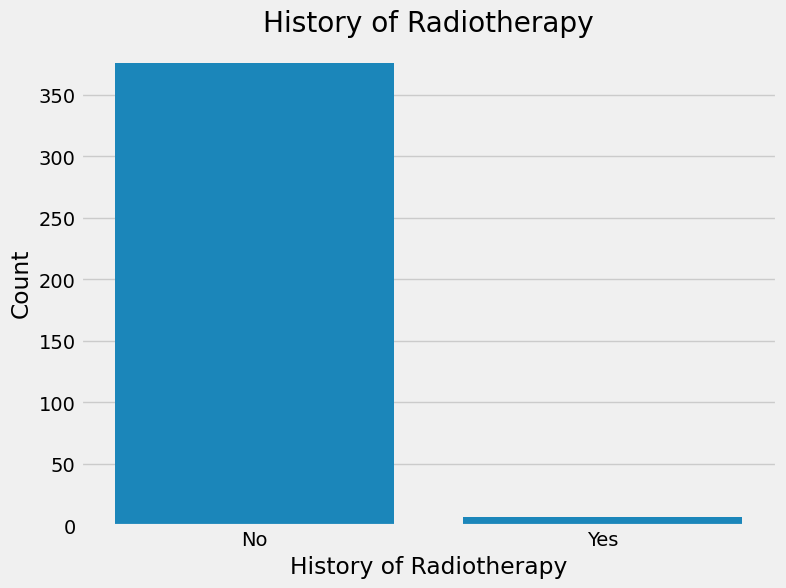

In [2196]:
#History of Radiotherapy
plt.figure(figsize = (8, 6))
sns.countplot(x = 'Hx Radiotherapy', data = df)
plt.title('History of Radiotherapy')
plt.xlabel('History of Radiotherapy')
plt.ylabel('Count')
plt.show()

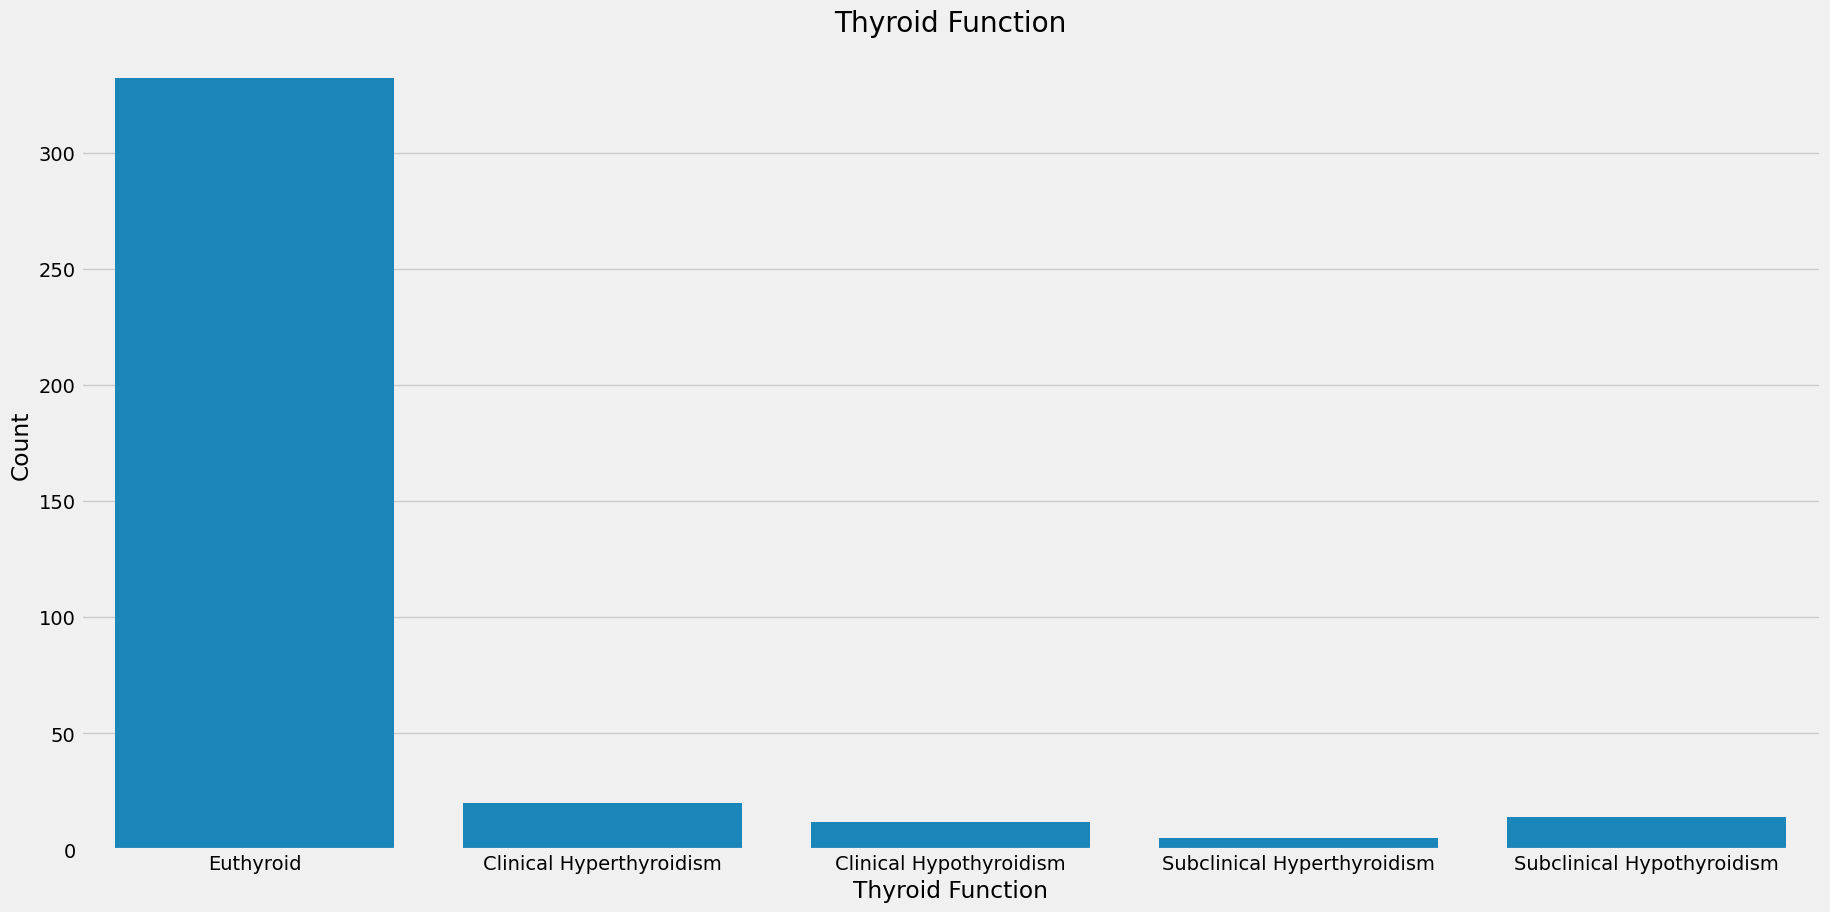

In [2197]:
#Thyroid Function
plt.figure(figsize = (20, 10))
sns.countplot(x = 'Thyroid Function', data = df)
plt.title('Thyroid Function')
plt.xlabel('Thyroid Function')
plt.ylabel('Count')
plt.show()

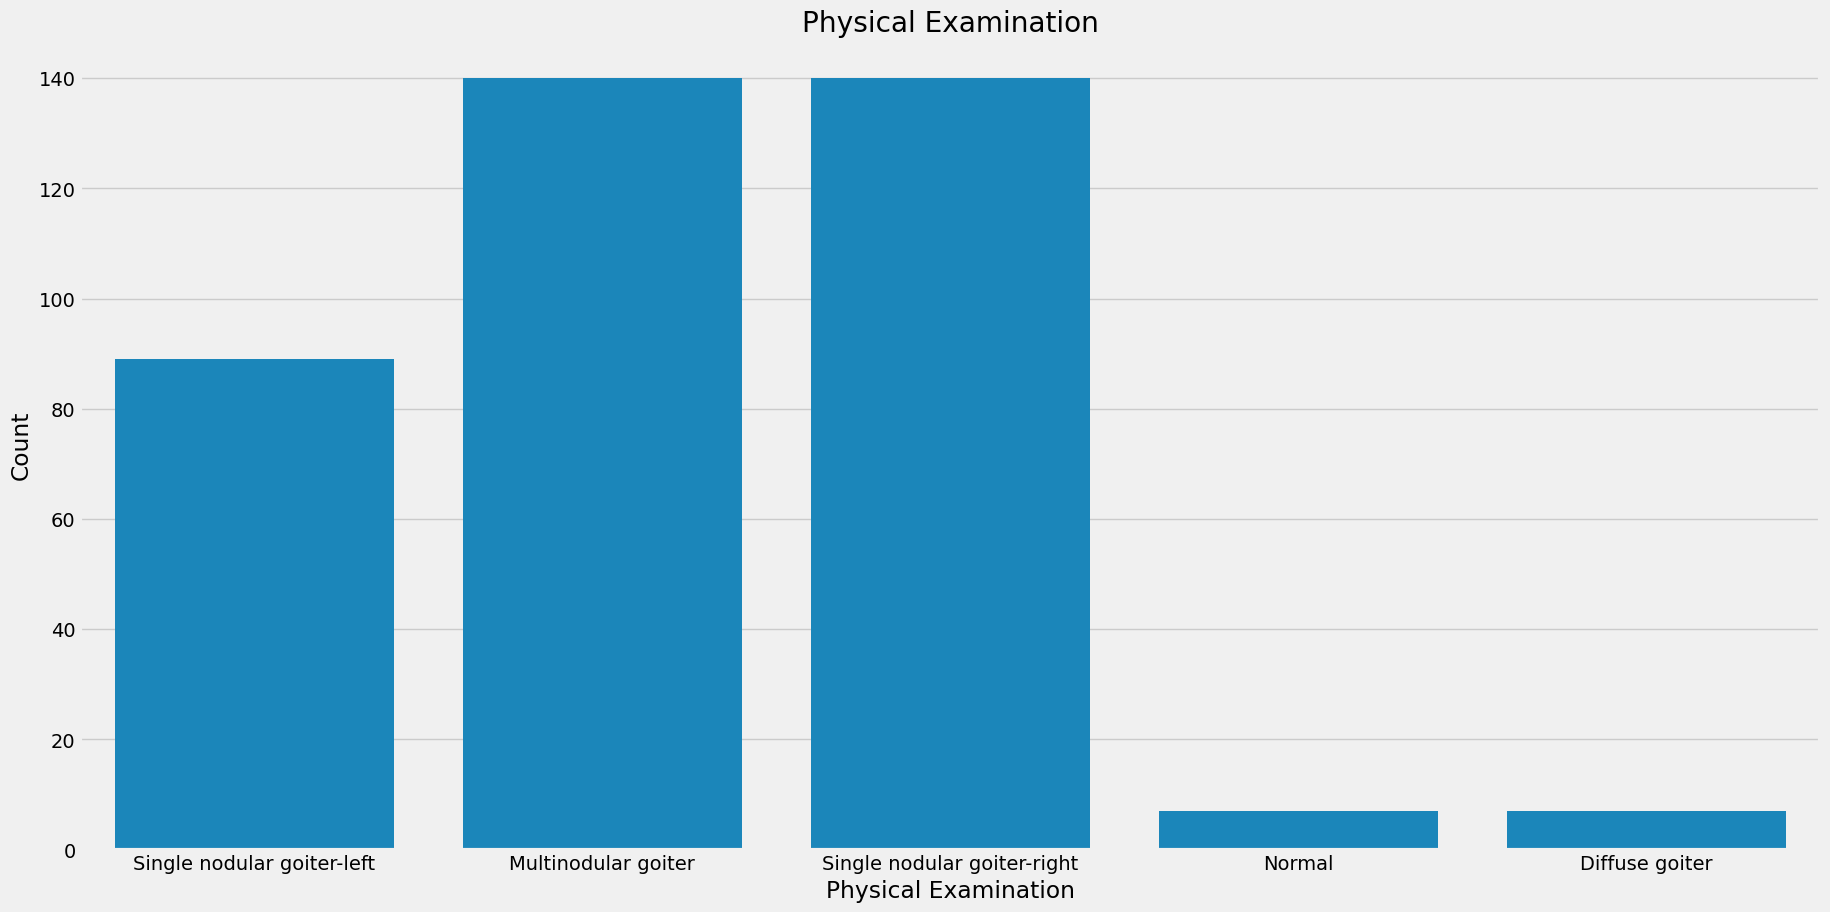

In [2198]:
#Physical Examination
plt.figure(figsize = (20, 10))
sns.countplot(x = 'Physical Examination', data = df)
plt.title('Physical Examination')
plt.xlabel('Physical Examination')
plt.ylabel('Count')
plt.show()

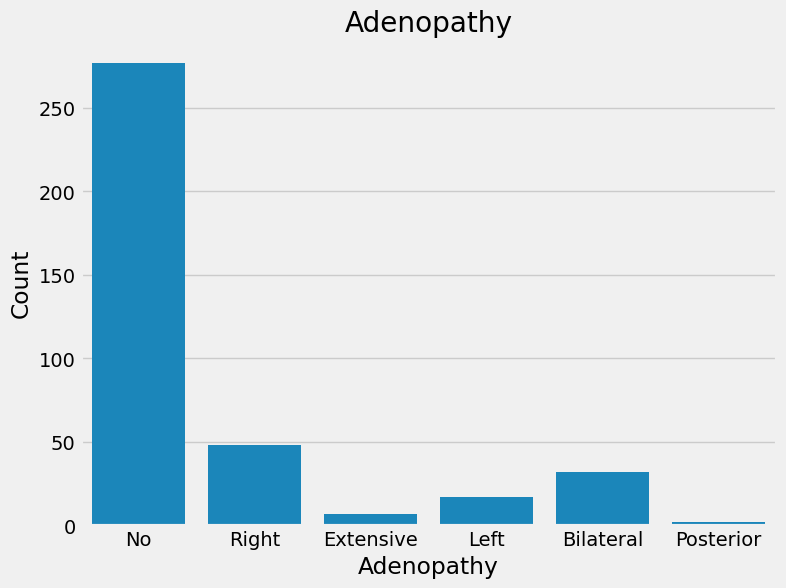

In [2199]:
#Adenopathy
plt.figure(figsize = (8, 6))
sns.countplot(x = 'Adenopathy', data = df)
plt.title('Adenopathy')
plt.xlabel('Adenopathy')
plt.ylabel('Count')
plt.show()

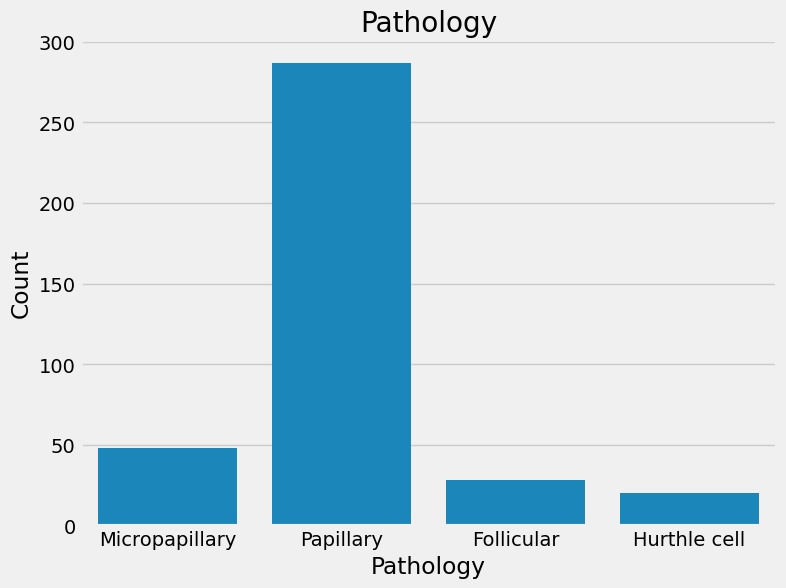

In [2200]:
#Pathology
plt.figure(figsize = (8, 6))
sns.countplot(x = 'Pathology', data = df)
plt.title('Pathology')
plt.xlabel('Pathology')
plt.ylabel('Count')
plt.show()

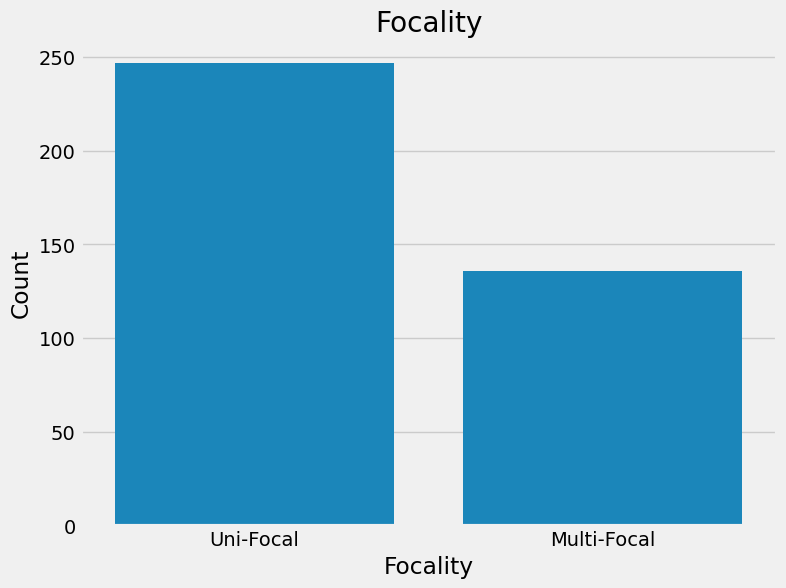

In [2201]:
#Focality
plt.figure(figsize = (8, 6))
sns.countplot(x = 'Focality', data = df)
plt.title('Focality')
plt.xlabel('Focality')
plt.ylabel('Count')
plt.show()

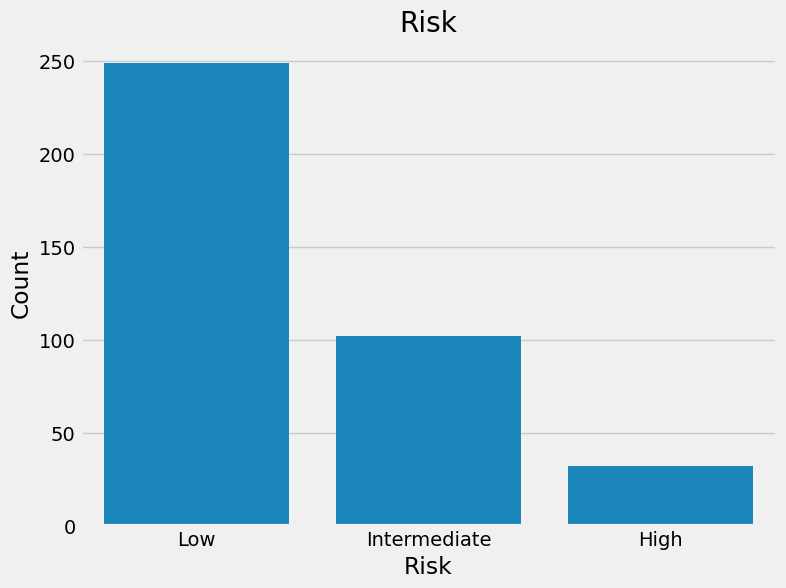

In [2202]:
#Risk
plt.figure(figsize = (8, 6))
sns.countplot(x = 'Risk', data = df)
plt.title('Risk')
plt.xlabel('Risk')
plt.ylabel('Count')
plt.show()

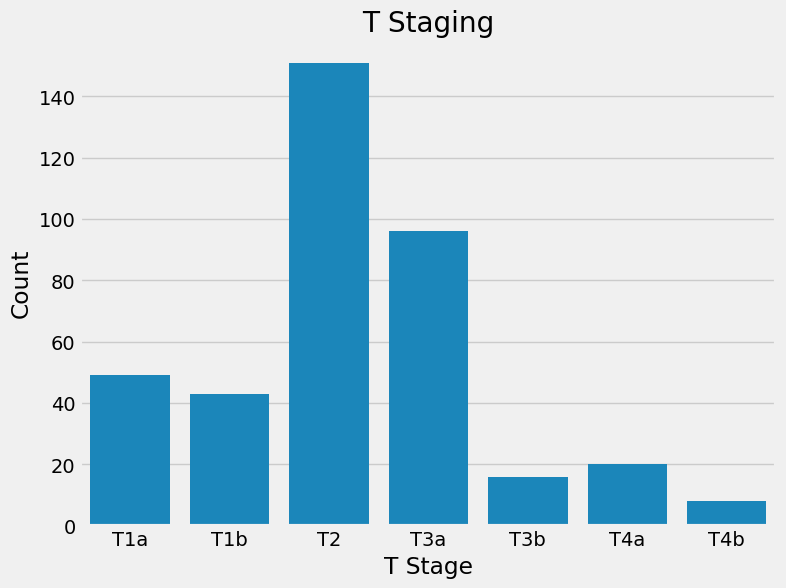

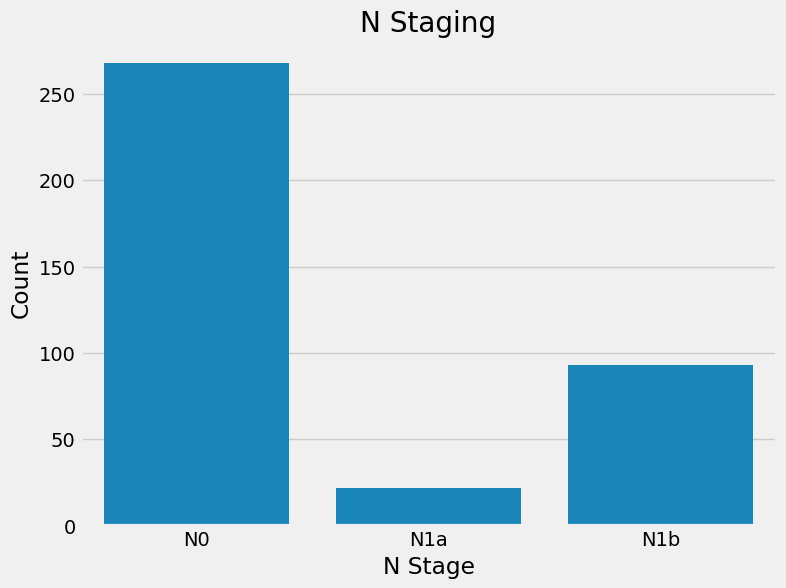

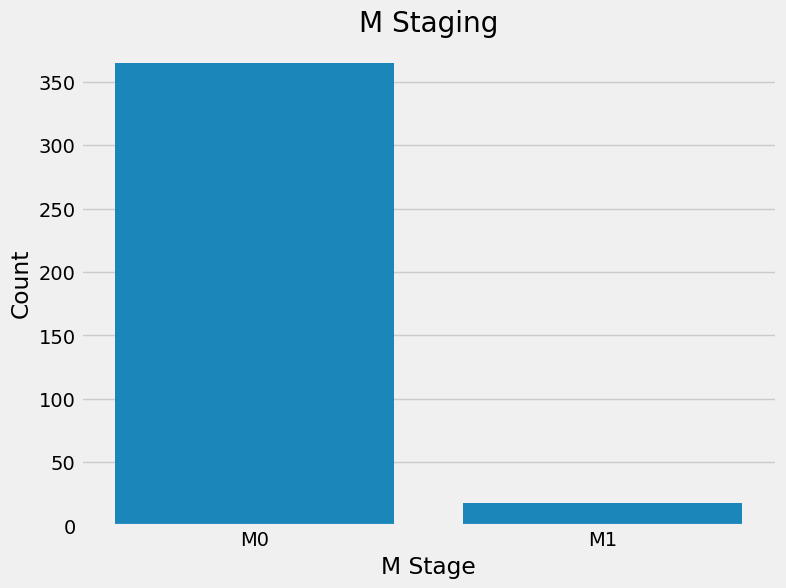

In [2203]:
#T, N, M (TNM Staging)
plt.figure(figsize = (8, 6))
sns.countplot(x = 'T', data = df, order = sorted(df['T'].unique()))
plt.title('T Staging')
plt.xlabel('T Stage')
plt.ylabel('Count')
plt.show()

plt.figure(figsize = (8, 6))
sns.countplot(x = 'N', data = df, order = sorted(df['N'].unique()))
plt.title('N Staging')
plt.xlabel('N Stage')
plt.ylabel('Count')
plt.show()

plt.figure(figsize = (8, 6))
sns.countplot(x = 'M', data = df, order = sorted(df['M'].unique()))
plt.title('M Staging')
plt.xlabel('M Stage')
plt.ylabel('Count')
plt.show()

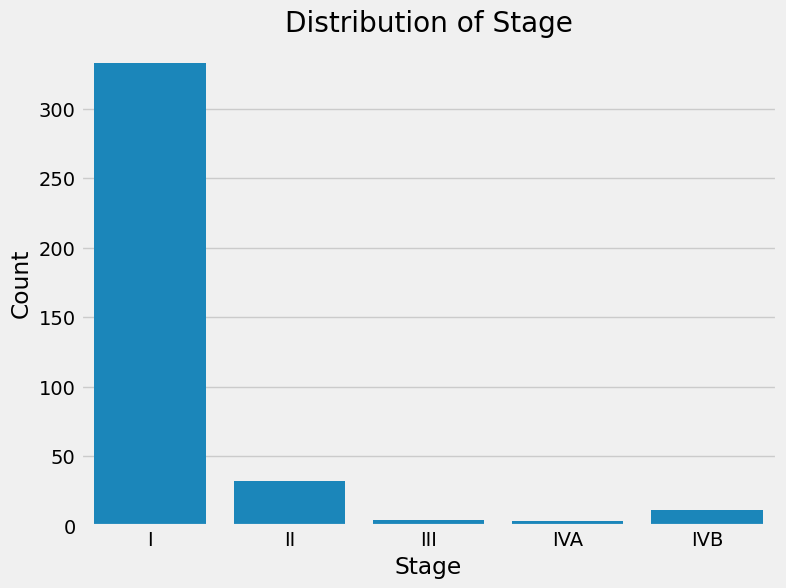

In [2204]:
#Stage
stage_order = ['I', 'II', 'III', 'IVA', 'IVB']

plt.figure(figsize = (8, 6))
sns.countplot(x = 'Stage', data = df, order = stage_order)  # Order the stages
plt.title('Distribution of Stage')
plt.xlabel('Stage')
plt.ylabel('Count')
plt.show()

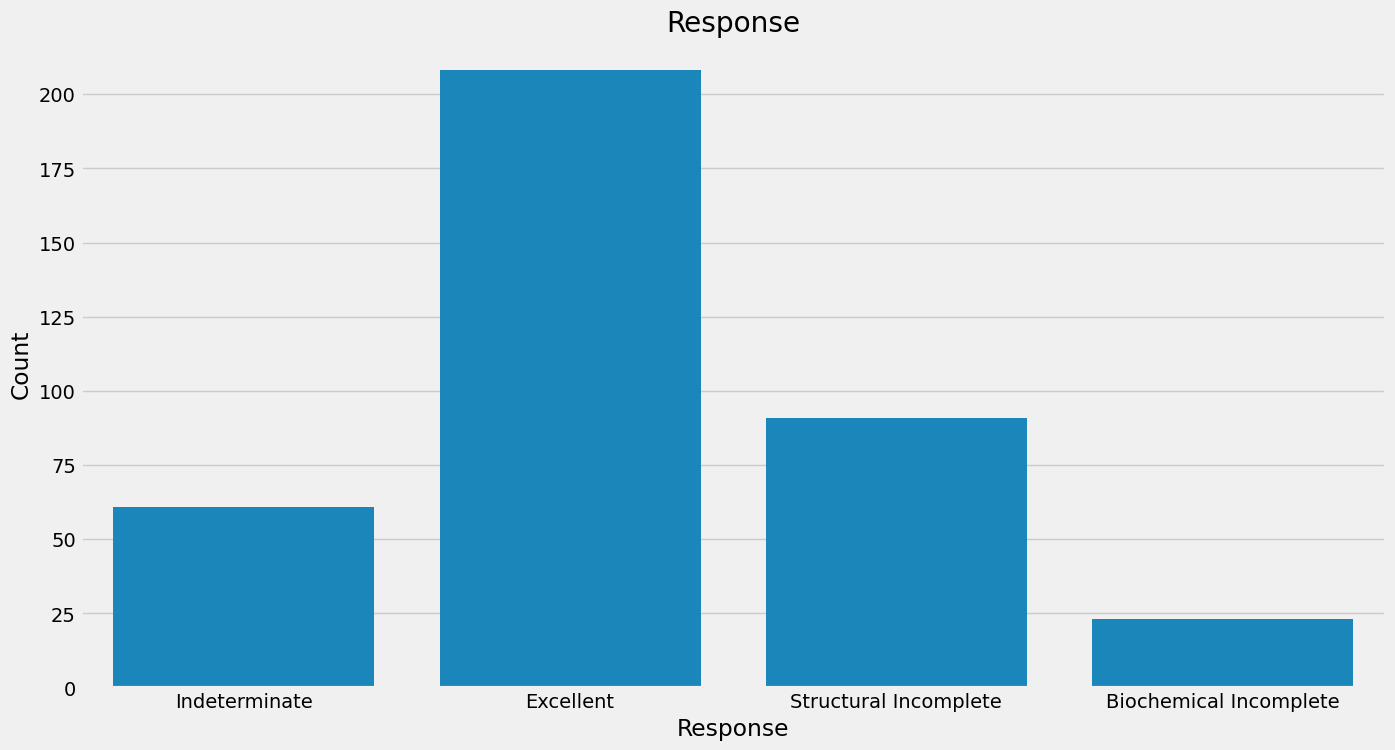

In [2205]:
#Response
plt.figure(figsize = (15, 8))
sns.countplot(x = 'Response', data = df)
plt.title('Response')
plt.xlabel('Response')
plt.ylabel('Count')
plt.show()

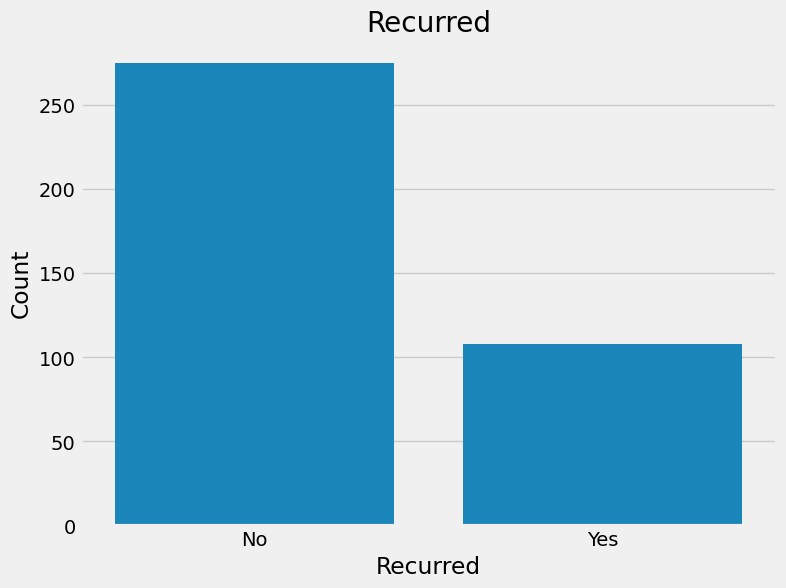

In [2206]:
#Recurred
plt.figure(figsize = (8, 6))
sns.countplot(x = 'Recurred', data = df)
plt.title('Recurred')
plt.xlabel('Recurred')
plt.ylabel('Count')
plt.show()

### 1.1.1 Label Encoding

In [2207]:
# Label encoding yes or no values

# Define mapping
mapping = {'No': 0, 'Yes': 1}

# TODO: Insert names of columns that have Yes or No values
boolean_columns = ['Smoking','Hx Smoking','Hx Radiotherapy','Recurred']
df[boolean_columns] = df[boolean_columns].map(mapping.get)

df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,0,0,0,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,0
1,34,F,0,1,0,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,0
2,30,F,0,0,0,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,0
3,62,F,0,0,0,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,0
4,62,F,0,0,0,Euthyroid,Multinodular goiter,No,Micropapillary,Multi-Focal,Low,T1a,N0,M0,I,Excellent,0


In [2208]:
# Label encode features with only 2 values
le = LabelEncoder()

# TODO: Input column names that only have 2 values
columns_to_encode = ['Gender','Focality','M']

for column in columns_to_encode:
  df[column] = le.fit_transform(df[column])

df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,0,0,0,0,Euthyroid,Single nodular goiter-left,No,Micropapillary,1,Low,T1a,N0,0,I,Indeterminate,0
1,34,0,0,1,0,Euthyroid,Multinodular goiter,No,Micropapillary,1,Low,T1a,N0,0,I,Excellent,0
2,30,0,0,0,0,Euthyroid,Single nodular goiter-right,No,Micropapillary,1,Low,T1a,N0,0,I,Excellent,0
3,62,0,0,0,0,Euthyroid,Single nodular goiter-right,No,Micropapillary,1,Low,T1a,N0,0,I,Excellent,0
4,62,0,0,0,0,Euthyroid,Multinodular goiter,No,Micropapillary,0,Low,T1a,N0,0,I,Excellent,0


### 1.1.2 Label Encoding with Order

In [2209]:
df['Physical Examination'].unique()

array(['Single nodular goiter-left', 'Multinodular goiter',
       'Single nodular goiter-right', 'Normal', 'Diffuse goiter'],
      dtype=object)

In [2210]:
# TODO: Define mapping for 'Physical Examination'
mapping = {'Normal': 0, 'Diffuse goiter':1, 'Single nodular goiter-left':2, 'Single nodular goiter-right':2,'Multinodular goiter':3}

df['Physical Examination'] = df['Physical Examination'].map(mapping)

if np.isnan(df['Physical Examination'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,0,0,0,0,Euthyroid,2,No,Micropapillary,1,Low,T1a,N0,0,I,Indeterminate,0
1,34,0,0,1,0,Euthyroid,3,No,Micropapillary,1,Low,T1a,N0,0,I,Excellent,0
2,30,0,0,0,0,Euthyroid,2,No,Micropapillary,1,Low,T1a,N0,0,I,Excellent,0
3,62,0,0,0,0,Euthyroid,2,No,Micropapillary,1,Low,T1a,N0,0,I,Excellent,0
4,62,0,0,0,0,Euthyroid,3,No,Micropapillary,0,Low,T1a,N0,0,I,Excellent,0


In [2211]:
df['Adenopathy'].unique()

array(['No', 'Right', 'Extensive', 'Left', 'Bilateral', 'Posterior'],
      dtype=object)

In [2212]:
# TODO: Define mapping for 'Adenopathy'
mapping = {'No': 0, 'Right':1, 'Left':1, 'Posterior':2,'Bilateral':3,'Extensive':4}

df['Adenopathy'] = df['Adenopathy'].map(mapping)

if np.isnan(df['Adenopathy'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,0,0,0,0,Euthyroid,2,0,Micropapillary,1,Low,T1a,N0,0,I,Indeterminate,0
1,34,0,0,1,0,Euthyroid,3,0,Micropapillary,1,Low,T1a,N0,0,I,Excellent,0
2,30,0,0,0,0,Euthyroid,2,0,Micropapillary,1,Low,T1a,N0,0,I,Excellent,0
3,62,0,0,0,0,Euthyroid,2,0,Micropapillary,1,Low,T1a,N0,0,I,Excellent,0
4,62,0,0,0,0,Euthyroid,3,0,Micropapillary,0,Low,T1a,N0,0,I,Excellent,0


In [2213]:
# TODO: Use the .unique() function to find the unique values for 'Pathology'
df['Pathology'].unique()


array(['Micropapillary', 'Papillary', 'Follicular', 'Hurthle cell'],
      dtype=object)

In [2214]:
# TODO: Define mapping for 'Pathology'
mapping = {'Micropapillary':0,'Papillary':1, 'Follicular':2, 'Hurthle cell':3}

df['Pathology'] = df['Pathology'].map(mapping)

if np.isnan(df['Pathology'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,0,0,0,0,Euthyroid,2,0,0,1,Low,T1a,N0,0,I,Indeterminate,0
1,34,0,0,1,0,Euthyroid,3,0,0,1,Low,T1a,N0,0,I,Excellent,0
2,30,0,0,0,0,Euthyroid,2,0,0,1,Low,T1a,N0,0,I,Excellent,0
3,62,0,0,0,0,Euthyroid,2,0,0,1,Low,T1a,N0,0,I,Excellent,0
4,62,0,0,0,0,Euthyroid,3,0,0,0,Low,T1a,N0,0,I,Excellent,0


In [2215]:
# TODO: Define mapping for 'Risk'
mapping = {'Low':0,'Intermediate':1, 'High':2}

df['Risk'] = df['Risk'].map(mapping)

if np.isnan(df['Risk'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,0,0,0,0,Euthyroid,2,0,0,1,0,T1a,N0,0,I,Indeterminate,0
1,34,0,0,1,0,Euthyroid,3,0,0,1,0,T1a,N0,0,I,Excellent,0
2,30,0,0,0,0,Euthyroid,2,0,0,1,0,T1a,N0,0,I,Excellent,0
3,62,0,0,0,0,Euthyroid,2,0,0,1,0,T1a,N0,0,I,Excellent,0
4,62,0,0,0,0,Euthyroid,3,0,0,0,0,T1a,N0,0,I,Excellent,0


In [2216]:
# TODO: Use the .unique() function to find the unique values for 'T'
df['T'].unique()

array(['T1a', 'T1b', 'T2', 'T3a', 'T3b', 'T4a', 'T4b'], dtype=object)

In [2217]:
# TODO: Define mapping for 'T'
mapping = {'T1a':0, 'T1b':1, 'T2':2, 'T3a':3, 'T3b':4, 'T4a':5, 'T4b':6}

df['T'] = df['T'].map(mapping)

if np.isnan(df['T'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,0,0,0,0,Euthyroid,2,0,0,1,0,0,N0,0,I,Indeterminate,0
1,34,0,0,1,0,Euthyroid,3,0,0,1,0,0,N0,0,I,Excellent,0
2,30,0,0,0,0,Euthyroid,2,0,0,1,0,0,N0,0,I,Excellent,0
3,62,0,0,0,0,Euthyroid,2,0,0,1,0,0,N0,0,I,Excellent,0
4,62,0,0,0,0,Euthyroid,3,0,0,0,0,0,N0,0,I,Excellent,0


In [2218]:
# TODO: Use the .unique() function to find the unique values for 'N'
df['N'].unique()


array(['N0', 'N1b', 'N1a'], dtype=object)

In [2219]:
# TODO: Define mapping for 'N'
mapping = {'N0':0, 'N1a':1, 'N1b':2}

df['N'] = df['N'].map(mapping)

if np.isnan(df['N'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,0,0,0,0,Euthyroid,2,0,0,1,0,0,0,0,I,Indeterminate,0
1,34,0,0,1,0,Euthyroid,3,0,0,1,0,0,0,0,I,Excellent,0
2,30,0,0,0,0,Euthyroid,2,0,0,1,0,0,0,0,I,Excellent,0
3,62,0,0,0,0,Euthyroid,2,0,0,1,0,0,0,0,I,Excellent,0
4,62,0,0,0,0,Euthyroid,3,0,0,0,0,0,0,0,I,Excellent,0


In [2220]:
# TODO: Use the .unique() function to find the unique values for 'Stage'
df['Stage'].unique()

array(['I', 'II', 'IVB', 'III', 'IVA'], dtype=object)

In [2221]:
# TODO: Define mapping for 'Stage'
mapping = {'I':0, 'II':1, 'III':2, 'IVA':3, 'IVB':4}

df['Stage'] = df['Stage'].map(mapping)

if np.isnan(df['Stage'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,0,0,0,0,Euthyroid,2,0,0,1,0,0,0,0,0,Indeterminate,0
1,34,0,0,1,0,Euthyroid,3,0,0,1,0,0,0,0,0,Excellent,0
2,30,0,0,0,0,Euthyroid,2,0,0,1,0,0,0,0,0,Excellent,0
3,62,0,0,0,0,Euthyroid,2,0,0,1,0,0,0,0,0,Excellent,0
4,62,0,0,0,0,Euthyroid,3,0,0,0,0,0,0,0,0,Excellent,0


Code Block 1Q

In [2222]:
# TODO: Use the .unique() function to find the unique values for 'Response'
df['Response'].unique()

array(['Indeterminate', 'Excellent', 'Structural Incomplete',
       'Biochemical Incomplete'], dtype=object)

In [2223]:
# TODO: Define mapping for 'Response'
mapping = {'Excellent':0, 'Indeterminate':1, 'Biochemical Incomplete':2, 'Structural Incomplete':3}

df['Response'] = df['Response'].map(mapping)

if np.isnan(df['Response'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,0,0,0,0,Euthyroid,2,0,0,1,0,0,0,0,0,1,0
1,34,0,0,1,0,Euthyroid,3,0,0,1,0,0,0,0,0,0,0
2,30,0,0,0,0,Euthyroid,2,0,0,1,0,0,0,0,0,0,0
3,62,0,0,0,0,Euthyroid,2,0,0,1,0,0,0,0,0,0,0
4,62,0,0,0,0,Euthyroid,3,0,0,0,0,0,0,0,0,0,0


### 1.1.3 One-Hot Encoding

In [2224]:
# Initialize a OneHotEncoder object
ohe = OneHotEncoder()

# Fit the OneHotEncoder to the 'Thyroid Function' column of the dataframe 'df'
# and transform it into a one-hot encoded array. The 'toarray()' method
# converts the sparse matrix output into a dense numpy array.
ohe.fit_transform(df[['Thyroid Function']]).toarray()

array([[0., 0., 1., 0., 0.],
       [0., 0., 1., 0., 0.],
       [0., 0., 1., 0., 0.],
       ...,
       [0., 0., 1., 0., 0.],
       [1., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0.]])

In [2225]:
# Fit the OneHotEncoder to the 'Thyroid Function' column of the dataframe 'df'
# and transform it into a one-hot encoded array. The 'toarray()' method
# converts the sparse matrix output into a dense numpy array.
feature_array = ohe.fit_transform(df[['Thyroid Function']]).toarray()

# Get the category labels from the fitted OneHotEncoder
feature_labels = ohe.categories_

# Convert the list of arrays (from ohe.categories_) to a flattened numpy array
feature_labels = np.array(feature_labels).ravel()

# Create a DataFrame from the one-hot encoded array with column names set to the flattened feature labels
pd.DataFrame(feature_array, columns=feature_labels)

,Clinical Hyperthyroidism,Clinical Hypothyroidism,Euthyroid,Subclinical Hyperthyroidism,Subclinical Hypothyroidism
0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0
4,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...
378,0.0,0.0,1.0,0.0,0.0
379,0.0,0.0,1.0,0.0,0.0
380,0.0,0.0,1.0,0.0,0.0
381,1.0,0.0,0.0,0.0,0.0


In [2226]:
# Create a DataFrame from the one-hot encoded array (feature_array)
# using the flattened feature labels (feature_labels) as column names
features = pd.DataFrame(feature_array, columns=feature_labels)

# Concatenate the original dataframe (df) and the new one-hot encoded features (features)
# along the columns (axis=1). This results in a combined DataFrame with both the original
# and one-hot encoded features.
pd.concat([df, features], axis=1)

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,...,N,M,Stage,Response,Recurred,Clinical Hyperthyroidism,Clinical Hypothyroidism,Euthyroid,Subclinical Hyperthyroidism,Subclinical Hypothyroidism
0,27,0,0,0,0,Euthyroid,2,0,0,1,...,0,0,0,1,0,0.0,0.0,1.0,0.0,0.0
1,34,0,0,1,0,Euthyroid,3,0,0,1,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
2,30,0,0,0,0,Euthyroid,2,0,0,1,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
3,62,0,0,0,0,Euthyroid,2,0,0,1,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
4,62,0,0,0,0,Euthyroid,3,0,0,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
378,72,1,1,1,1,Euthyroid,2,1,1,1,...,2,1,4,2,1,0.0,0.0,1.0,0.0,0.0
379,81,1,1,0,1,Euthyroid,3,4,1,0,...,2,1,4,3,1,0.0,0.0,1.0,0.0,0.0
380,72,1,1,1,0,Euthyroid,3,3,1,0,...,2,1,4,3,1,0.0,0.0,1.0,0.0,0.0
381,61,1,1,1,1,Clinical Hyperthyroidism,3,4,3,0,...,2,0,3,3,1,1.0,0.0,0.0,0.0,0.0


In [2227]:
# Concatenate the original dataframe (df) with the new one-hot encoded features (features)
# along the columns (axis=1). This adds the one-hot encoded columns to the original dataframe.
df = pd.concat([df, features], axis=1)

# Drop the original 'Thyroid Function' column from the dataframe
# as it has been replaced by the one-hot encoded columns.
df = df.drop(['Thyroid Function'], axis='columns')

# Display the first few rows of the updated dataframe to inspect the result.
df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Physical Examination,Adenopathy,Pathology,Focality,Risk,...,N,M,Stage,Response,Recurred,Clinical Hyperthyroidism,Clinical Hypothyroidism,Euthyroid,Subclinical Hyperthyroidism,Subclinical Hypothyroidism
0,27,0,0,0,0,2,0,0,1,0,...,0,0,0,1,0,0.0,0.0,1.0,0.0,0.0
1,34,0,0,1,0,3,0,0,1,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
2,30,0,0,0,0,2,0,0,1,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
3,62,0,0,0,0,2,0,0,1,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
4,62,0,0,0,0,3,0,0,0,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0


In [2228]:
df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Physical Examination,Adenopathy,Pathology,Focality,Risk,...,N,M,Stage,Response,Recurred,Clinical Hyperthyroidism,Clinical Hypothyroidism,Euthyroid,Subclinical Hyperthyroidism,Subclinical Hypothyroidism
0,27,0,0,0,0,2,0,0,1,0,...,0,0,0,1,0,0.0,0.0,1.0,0.0,0.0
1,34,0,0,1,0,3,0,0,1,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
2,30,0,0,0,0,2,0,0,1,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
3,62,0,0,0,0,2,0,0,1,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
4,62,0,0,0,0,3,0,0,0,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0


In [2229]:
#apply Box-Cox transformation to 'Age' column
age_boxcox, _ = stats.boxcox(df['Age'])

#apply Min-Max scaling to the transformed 'Age' column
scaler = MinMaxScaler()
age_scaled = scaler.fit_transform(age_boxcox.reshape(-1, 1)).flatten()

#replace 'Age' column with the scaled values
df['Age'] = age_scaled

df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Physical Examination,Adenopathy,Pathology,Focality,Risk,...,N,M,Stage,Response,Recurred,Clinical Hyperthyroidism,Clinical Hypothyroidism,Euthyroid,Subclinical Hyperthyroidism,Subclinical Hypothyroidism
0,0.363135,0,0,0,0,2,0,0,1,0,...,0,0,0,1,0,0.0,0.0,1.0,0.0,0.0
1,0.500483,0,0,1,0,3,0,0,1,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
2,0.426257,0,0,0,0,2,0,0,1,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
3,0.845554,0,0,0,0,2,0,0,1,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
4,0.845554,0,0,0,0,3,0,0,0,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0


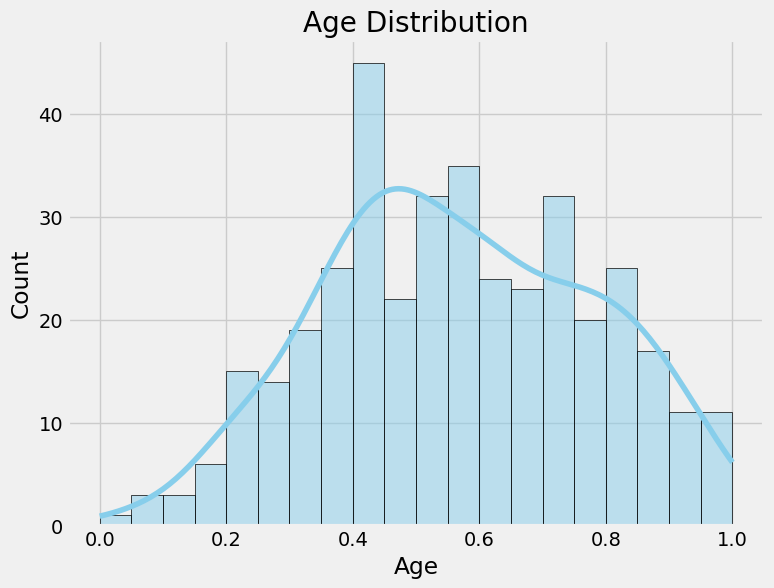

In [2230]:
#Age distribution after normalizing and scaling
plt.figure(figsize = (8, 6))
sns.histplot(df['Age'], bins = 20, kde = True, color = 'skyblue', edgecolor = 'black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

In [2231]:
# plt.figure(figsize=(12,6))
# sns.heatmap(cmap="coolwarm",fmt=".01f",annot=True,data=df.corr())

### 1.1.4 Split to Train and Test

In [2232]:
# Drop the 'Recurred' column from the DataFrame to create the input features DataFrame
inputs = df.drop('Recurred', axis='columns')

# Select the target column 'Recurred' from the DataFrame to create the target DataFrame
target = df['Recurred']

inputs.head()


,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Clinical Hyperthyroidism,Clinical Hypothyroidism,Euthyroid,Subclinical Hyperthyroidism,Subclinical Hypothyroidism
0,0.363135,0,0,0,0,2,0,0,1,0,0,0,0,0,1,0.0,0.0,1.0,0.0,0.0
1,0.500483,0,0,1,0,3,0,0,1,0,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
2,0.426257,0,0,0,0,2,0,0,1,0,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
3,0.845554,0,0,0,0,2,0,0,1,0,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
4,0.845554,0,0,0,0,3,0,0,0,0,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0


In [2233]:
# Split the data into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(inputs, target, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (306, 20)
X_test shape: (77, 20)
y_train shape: (306,)
y_test shape: (77,)


## 1.2 Train the Model

In [2234]:
# Creating a Decision Tree Classifier model object
#model = RandomForestClassifier()

In [2235]:
# Fitting the model to the training data (X_train) and corresponding labels (y_train)
#model.fit(X_train, y_train)

Decision Tree Accuracy 0.974025974025974
Decision Tree Important Features


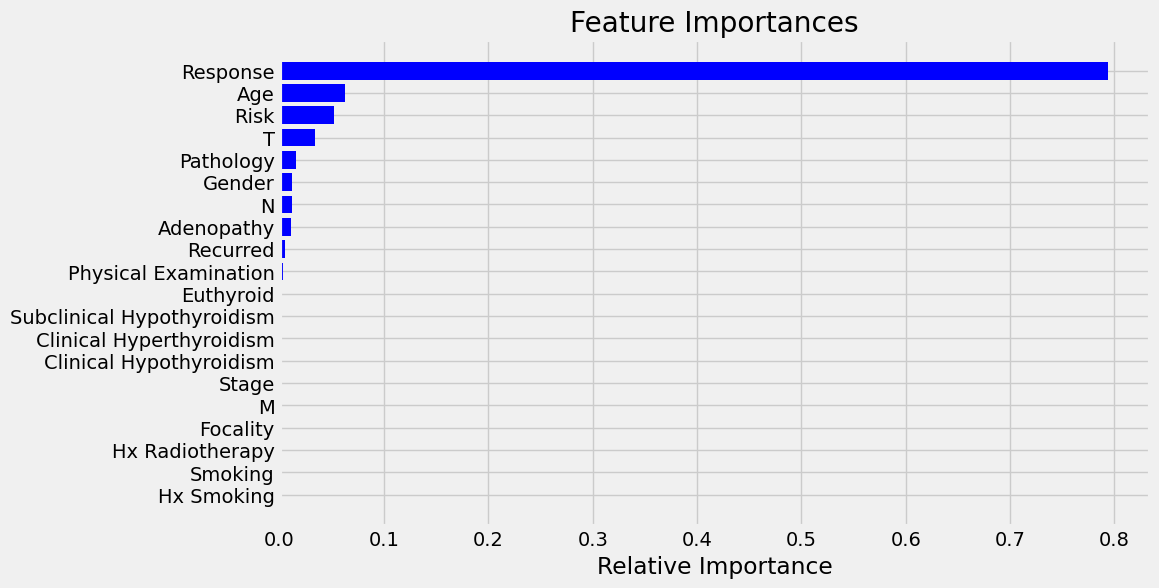

Random Forest Accuracy 0.987012987012987
Random Forest Important Features


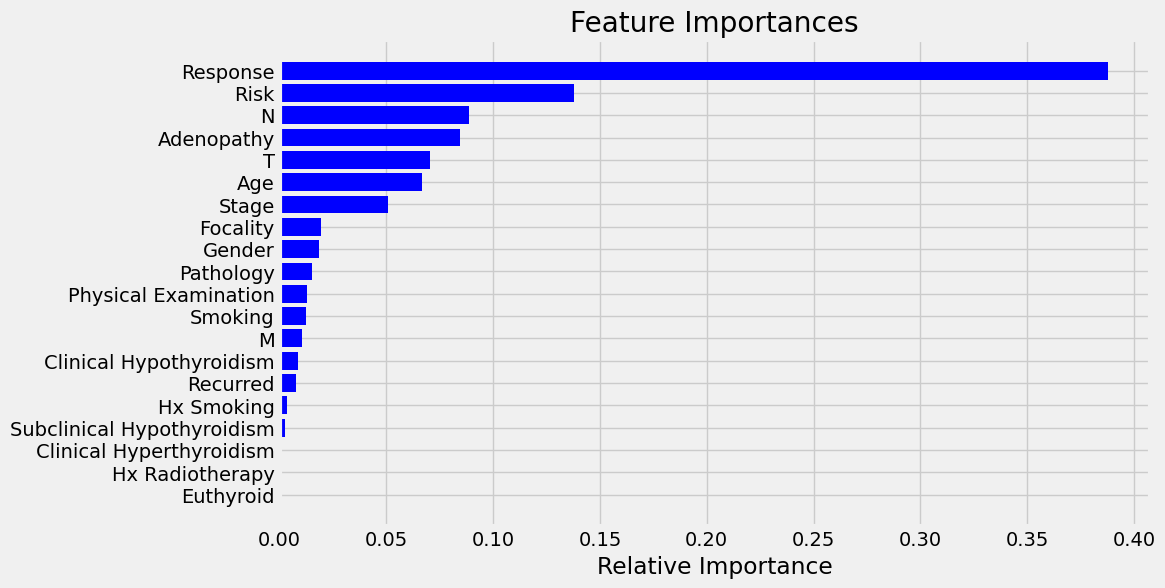

K-Nearest Neighbors Accuracy 0.961038961038961
Logistic Regression Accuracy 0.987012987012987
Support Vector Machine Accuracy 0.974025974025974
Gaussian Naive Bayes Accuracy 0.961038961038961
AdaBoost Accuracy 0.961038961038961
AdaBoost Important Features


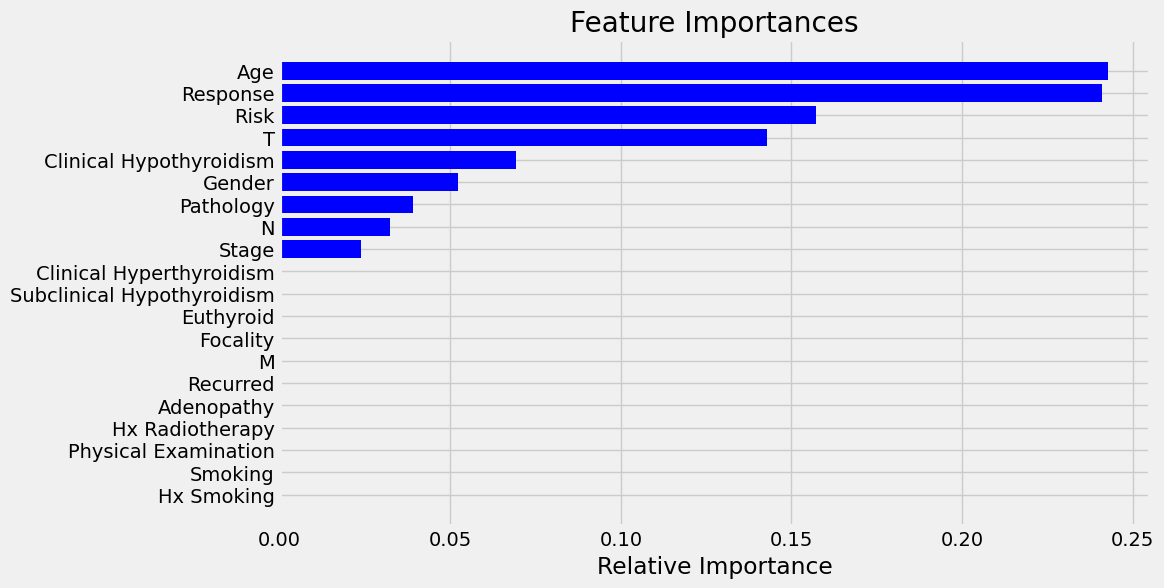

Gradient Boosting Accuracy 0.974025974025974
Gradient Boosting Important Features


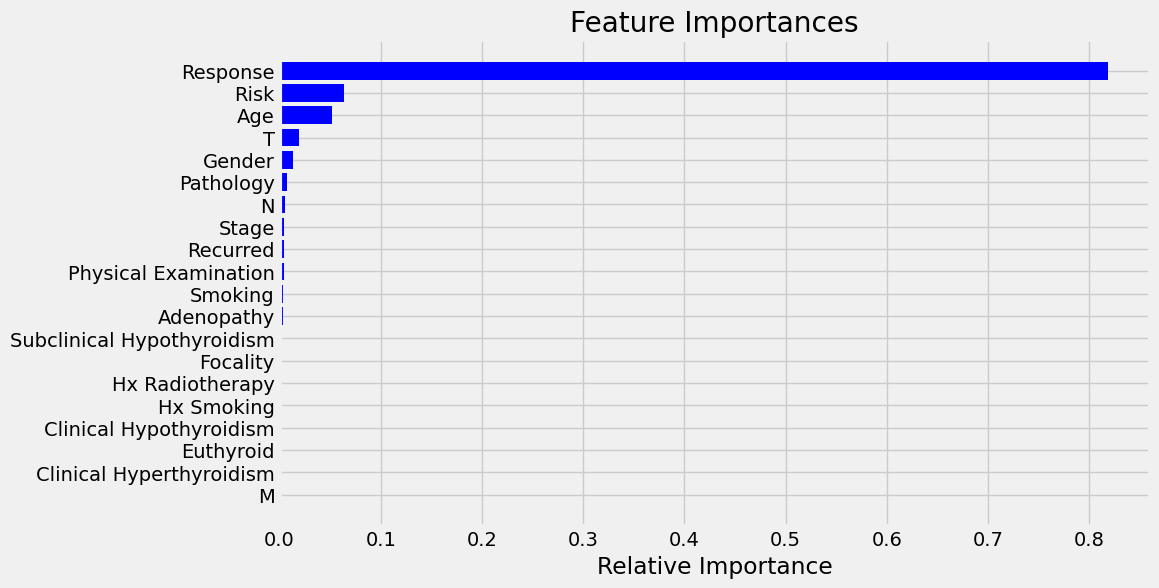

XGBoost Accuracy 0.974025974025974
XGBoost Important Features


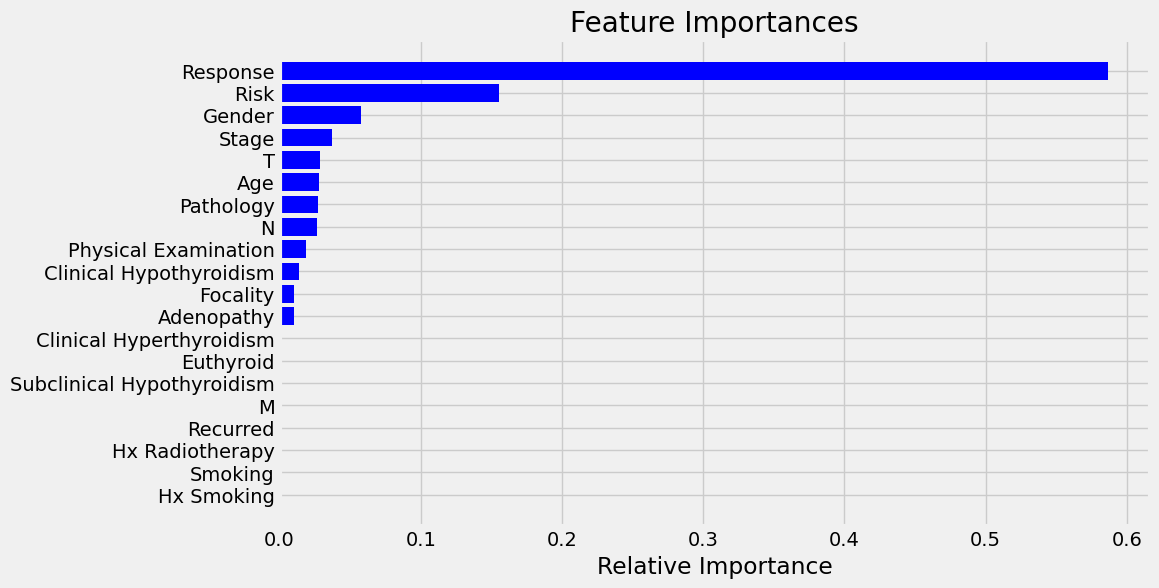

CatBoost Accuracy 0.987012987012987
CatBoost Important Features


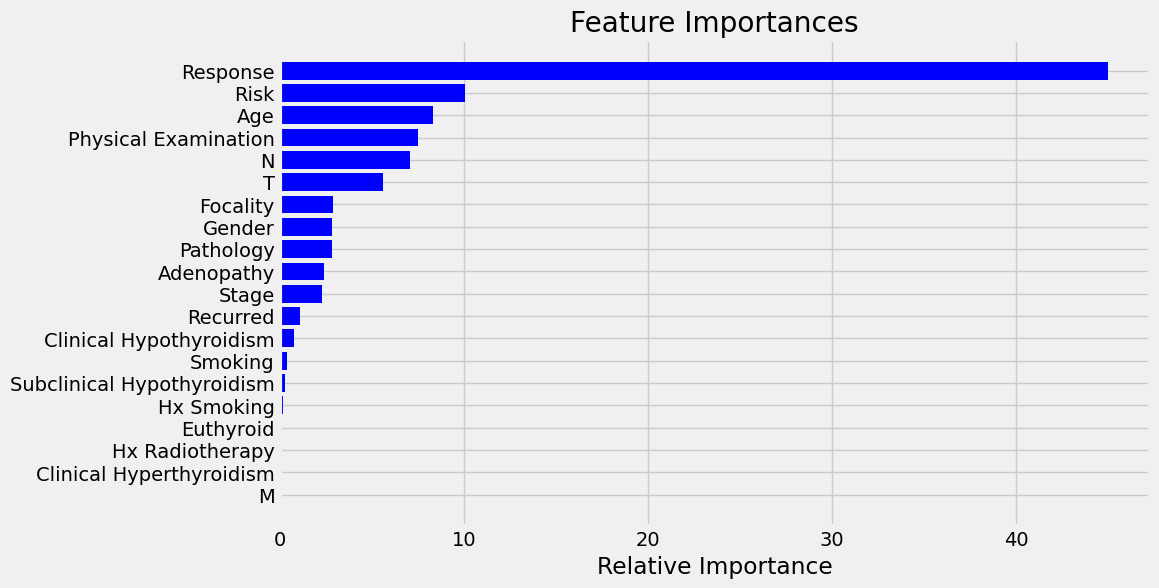

accuracy score of  K-Nearest Neighbors is 0.961038961038961
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.97        58
           1       0.94      0.89      0.92        19

    accuracy                           0.96        77
   macro avg       0.96      0.94      0.95        77
weighted avg       0.96      0.96      0.96        77


accuracy score of  Gaussian Naive Bayes is 0.961038961038961
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.97        58
           1       0.94      0.89      0.92        19

    accuracy                           0.96        77
   macro avg       0.96      0.94      0.95        77
weighted avg       0.96      0.96      0.96        77


accuracy score of  AdaBoost is 0.961038961038961
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.97      0.97       

In [2236]:
#instantiate classification models
models = {
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Logistic Regression': LogisticRegression(),
    'Support Vector Machine': SVC(),
    'Gaussian Naive Bayes': GaussianNB(),
    'AdaBoost': AdaBoostClassifier(),
    'Gradient Boosting': GradientBoostingClassifier(),
    'XGBoost': XGBClassifier(),
    'CatBoost': CatBoostClassifier(verbose=0)
}

#fit models and generate classification reports
model_scores = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Evaluating the trained model's performance on the test data (X_test) and corresponding labels (y_test)
    model.score(X_test, y_test)

    metric = accuracy_score(y_test , y_pred)
    report = classification_report(y_test, y_pred)
    model_scores.append((name , metric, report))

    print("{0} Accuracy {1}".format(name, accuracy_score(y_test, y_pred)))

    plt.figure(figsize=(10,7))
    sns.heatmap(confusion_matrix(y_test , y_pred) , annot=True , fmt='d')
    plt.xlabel('Prediction')
    plt.ylabel('Actual')
    
    # Feature importance
    feature_names = list(df.columns)
    feature_names.pop(19)

    if hasattr(model, "feature_importances_"):
        print("{0} Important Features".format(name))
        importances = model.feature_importances_
        indices = np.argsort(importances)

        # Plot feature importance
        plt.figure(figsize=(10, 6))
        plt.title('Feature Importances')
        plt.barh(range(len(indices)), importances[indices], color='b', align='center')
        plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
        plt.xlabel('Relative Importance')
        plt.show()

    # print("{0} Accuracy {1}".format(name, accuracy_score(y_test, y_pred)))
    # report = classification_report(y_test, y_pred)
    # print(f'Classification Report:\n{report}\n')

    # # Predict probabilities
    # y_prob = model.predict_proba(X_test)[:, 1]

    # # Compute ROC curve and AUC score
    # fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    # auc_score = roc_auc_score(y_test, y_prob)

    # # Plot the ROC curve
    # plt.figure(figsize=(8, 6))
    # plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc_score:.2f})')
    # plt.plot([0, 1], [0, 1], color='red', linestyle='--')
    # plt.xlabel('False Positive Rate')
    # plt.ylabel('True Positive Rate')
    # plt.title('Receiver Operating Characteristic (ROC) Curve')
    # plt.legend(loc='lower right')
    # plt.show()

sm = sorted(model_scores , key=lambda x :x[1] ,reverse = False)

for model in sm:
    print('accuracy score of ' , f'{model[0]} is {model[1]}')
    print(f'Classification Report:\n{model[2]}\n')

## 1.3 Evaluate the Model

In [2237]:
# # Evaluating the trained model's performance on the test data (X_test) and corresponding labels (y_test)
# model.score(X_test, y_test)

y_test = Actual Group

y_pred = Predicted Group

In [2238]:
# # Printing out the original group to compare
# y_test = y_test.to_numpy()

# print(y_test)

In [2239]:
# # Using the trained model to make predictions on the test data (X_test)
# y_pred = model.predict(X_test)

# # Printing the predicted labels
# print(y_pred)

## 1.4 Visualize the Model

In [2240]:
# TODO: Change this value to view the other decision trees
##tree_number = 0

# TODO: Change this value to change the depth of the decision tree
##max_depth = 2

##feature_names = list(df.columns)
##feature_names.pop(15)

# Plot the first tree
##plt.figure(figsize=(20, 10))
##plot_tree(model.estimators_[tree_number], feature_names=feature_names, max_depth=max_depth, filled=True)
##plt.show()

# Highlight Important Features

In [2241]:
# Feature importance
##importances = model.feature_importances_
##indices = np.argsort(importances)

# Plot feature importance
##plt.figure(figsize=(10, 6))
##plt.title('Feature Importances')
##plt.barh(range(len(indices)), importances[indices], color='b', align='center')
##plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
##plt.xlabel('Relative Importance')
##plt.show()

# Explain Model Performance

In [2242]:
# Create object that can calculate shap values
#explainer = shap.TreeExplainer(model)
##explainer = shap.TreeExplainer(model)

# Calculate Shap values
#shap_values = explainer.shap_values(X_test)

#All Rows
#shap.summary_plot(shap_values, X_test)
#Single Row
#shap.summary_plot(shap_values[0], X_test)
#shap.plots.force(explainer.expected_value[1], shap_values[1][2,:], X_test.iloc[2, :], matplotlib = True)

#shap.initjs()
#shap.force_plot(explainer.expected_value[0], shap_values[0], X_test)

#shap.decision_plot(explainer.expected_value[0], shap_values[0], X_test.columns)
#shap.decision_plot(explainer.expected_value[1], shap_values[1], X_test.columns)

##plt.figure(figsize=(10,7))
##sns.heatmap(confusion_matrix(y_test , y_pred) , annot=True , fmt='d')
##plt.xlabel('prediction')
##plt.ylabel('Actual')

In [2243]:
# # Predict probabilities
# y_prob = model.predict_proba(X_test)[:, 1]

# # Compute ROC curve and AUC score
# fpr, tpr, thresholds = roc_curve(y_test, y_prob)
# auc_score = roc_auc_score(y_test, y_prob)

# # Plot the ROC curve
# plt.figure(figsize=(8, 6))
# plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc_score:.2f})')
# plt.plot([0, 1], [0, 1], color='red', linestyle='--')
# plt.xlabel('False Positive Rate')
# plt.ylabel('True Positive Rate')
# plt.title('Receiver Operating Characteristic (ROC) Curve')
# plt.legend(loc='lower right')
# plt.show()

# 2. Process the Data Again with Fewer Features

## 2.1 Preprocess the Dataset

### 2.1.1 Select the Top 3 Columns



In [2244]:
df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Physical Examination,Adenopathy,Pathology,Focality,Risk,...,N,M,Stage,Response,Recurred,Clinical Hyperthyroidism,Clinical Hypothyroidism,Euthyroid,Subclinical Hyperthyroidism,Subclinical Hypothyroidism
0,0.363135,0,0,0,0,2,0,0,1,0,...,0,0,0,1,0,0.0,0.0,1.0,0.0,0.0
1,0.500483,0,0,1,0,3,0,0,1,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
2,0.426257,0,0,0,0,2,0,0,1,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
3,0.845554,0,0,0,0,2,0,0,1,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0
4,0.845554,0,0,0,0,3,0,0,0,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0


In [2245]:
# TODO: List the columns you want to keep here (dropped ..)
# df = df[['Age','Gender','Smoking','Hx Smoking','Hx Radiotherapy', 'Physical Examination', 'Adenopathy', 'Pathology', 'Focality', 'Risk', 'T', 'N', 'M', 'Stage', 'Response', 'Recurred', 'Clinical Hyperthyroidism', 'Clinical Hypothyroidism', 'Euthyroid', 'Subclinical Hyperthyroidism', 'Subclinical Hypothyroidism']]
# df = df[['Age','Gender','Smoking','Hx Smoking','Hx Radiotherapy', 'Physical Examination', 'Adenopathy', 'Pathology', 'Focality', 'Stage', 'Response', 'Recurred', 'Clinical Hyperthyroidism', 'Clinical Hypothyroidism', 'Euthyroid', 'Subclinical Hyperthyroidism', 'Subclinical Hypothyroidism']]
df = df.drop(['Focality', 'Stage','Risk', 'T', 'N', 'M'], axis='columns')
df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Physical Examination,Adenopathy,Pathology,Response,Recurred,Clinical Hyperthyroidism,Clinical Hypothyroidism,Euthyroid,Subclinical Hyperthyroidism,Subclinical Hypothyroidism
0,0.363135,0,0,0,0,2,0,0,1,0,0.0,0.0,1.0,0.0,0.0
1,0.500483,0,0,1,0,3,0,0,0,0,0.0,0.0,1.0,0.0,0.0
2,0.426257,0,0,0,0,2,0,0,0,0,0.0,0.0,1.0,0.0,0.0
3,0.845554,0,0,0,0,2,0,0,0,0,0.0,0.0,1.0,0.0,0.0
4,0.845554,0,0,0,0,3,0,0,0,0,0.0,0.0,1.0,0.0,0.0


### 2.1.2 Split to Train and Test

In [2246]:
inputs = df.drop('Recurred', axis='columns')
target = df['Recurred']

In [2247]:
# Split the data into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(inputs, target, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (306, 14)
X_test shape: (77, 14)
y_train shape: (306,)
y_test shape: (77,)


## 2.2 Train the Model

In [2248]:
# Creating a Decision Tree Classifier model object
#model = RandomForestClassifier()

In [2249]:
# Fitting the model to the training data (X_train) and corresponding labels (y_train)
#model.fit(X_train, y_train)

Decision Tree Accuracy 0.974025974025974
Decision Tree Important Features


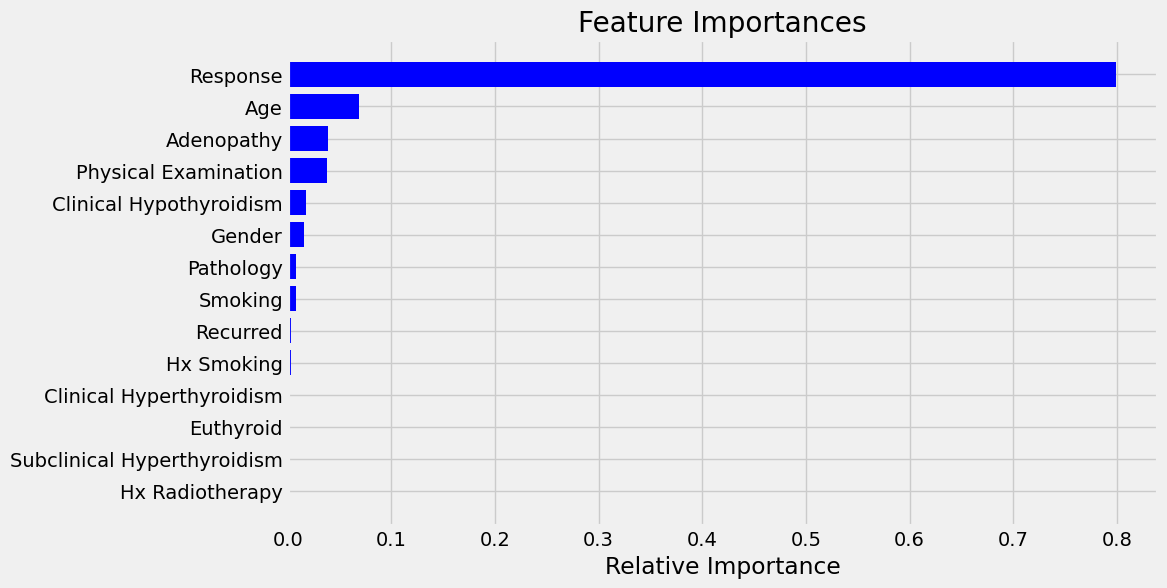

Random Forest Accuracy 0.987012987012987
Random Forest Important Features


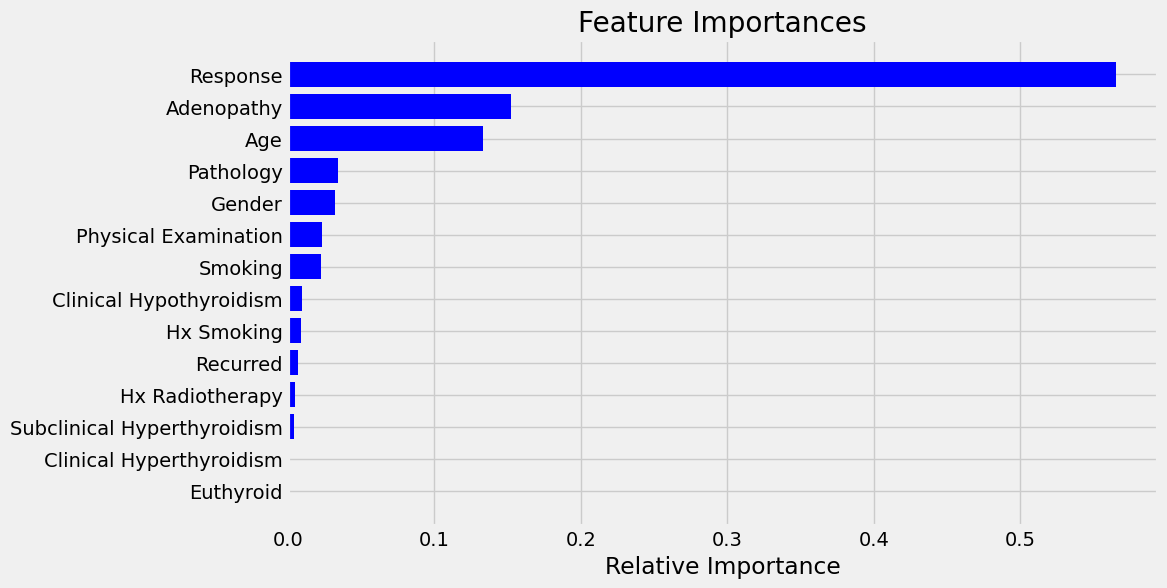

K-Nearest Neighbors Accuracy 0.987012987012987
Logistic Regression Accuracy 0.974025974025974
Support Vector Machine Accuracy 0.974025974025974
Gaussian Naive Bayes Accuracy 0.9090909090909091
AdaBoost Accuracy 0.974025974025974
AdaBoost Important Features


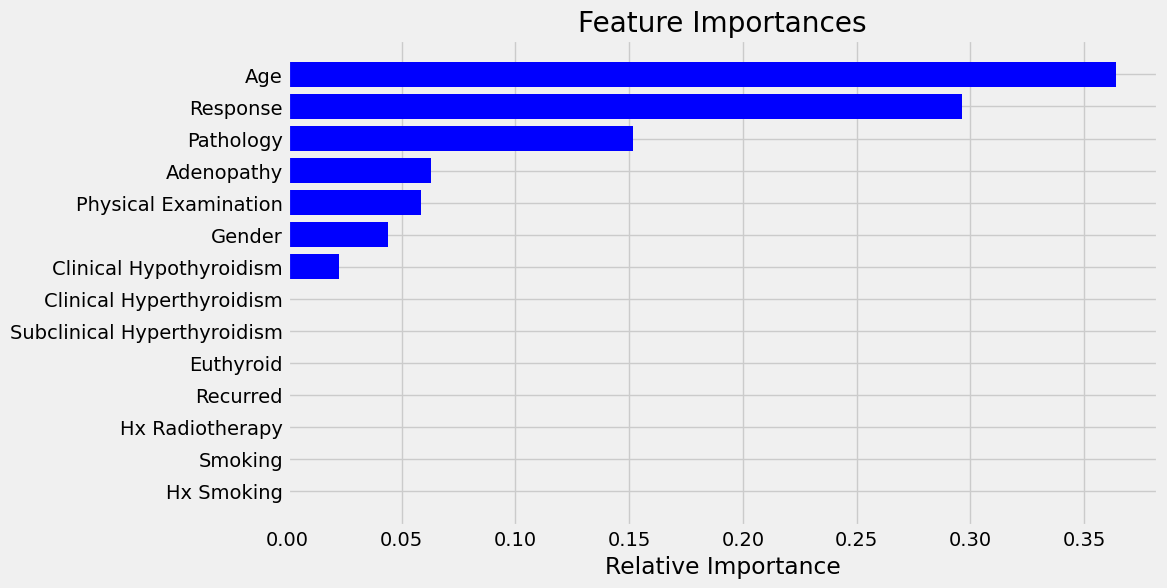

Gradient Boosting Accuracy 0.974025974025974
Gradient Boosting Important Features


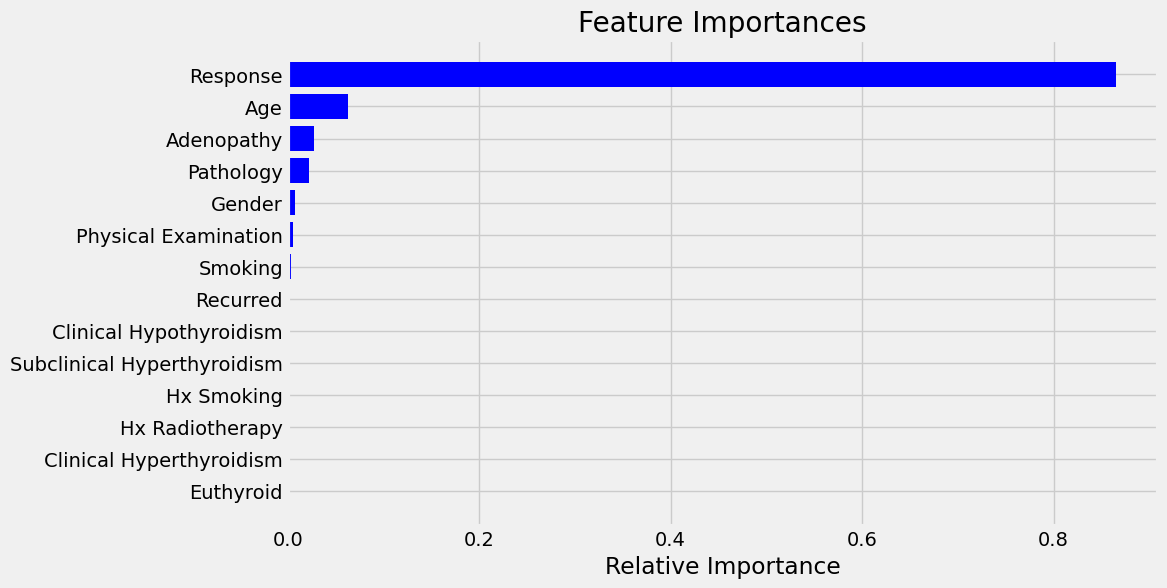

XGBoost Accuracy 1.0
XGBoost Important Features


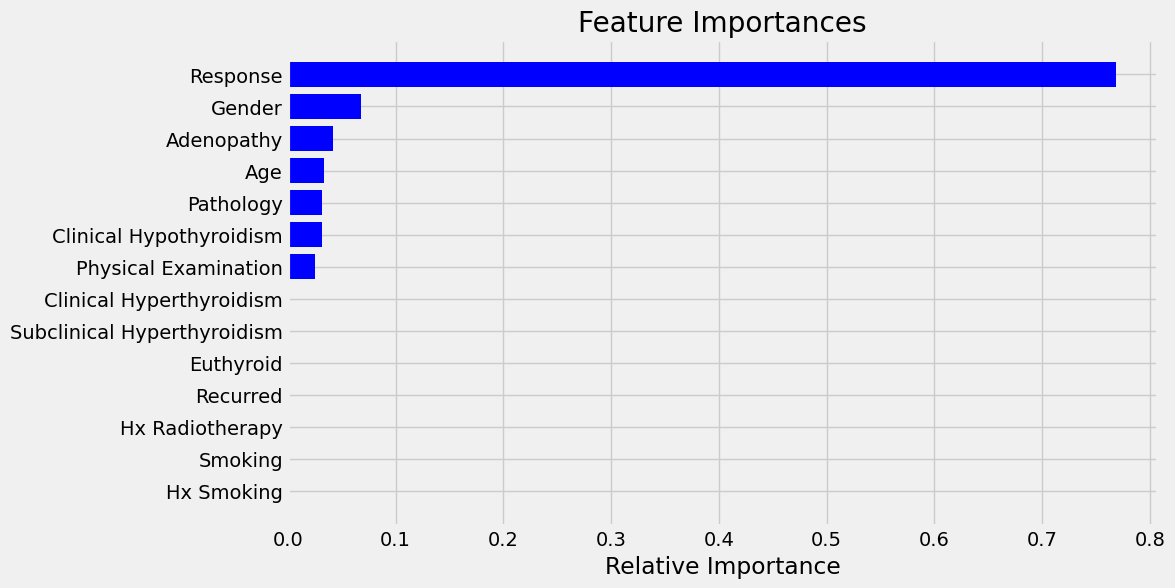

CatBoost Accuracy 1.0
CatBoost Important Features


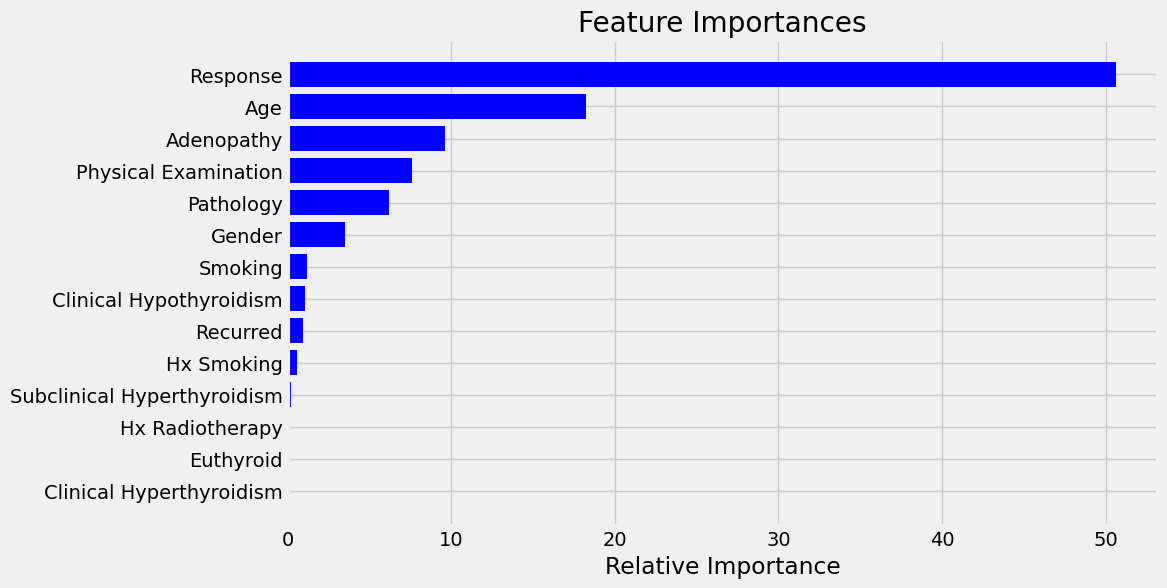

accuracy score of  Gaussian Naive Bayes is 0.9090909090909091
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.90      0.94        58
           1       0.75      0.95      0.84        19

    accuracy                           0.91        77
   macro avg       0.87      0.92      0.89        77
weighted avg       0.92      0.91      0.91        77


accuracy score of  Decision Tree is 0.974025974025974
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98        58
           1       0.90      1.00      0.95        19

    accuracy                           0.97        77
   macro avg       0.95      0.98      0.97        77
weighted avg       0.98      0.97      0.97        77


accuracy score of  Logistic Regression is 0.974025974025974
Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98 

In [2250]:
#instantiate classification models
models = {
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Logistic Regression': LogisticRegression(),
    'Support Vector Machine': SVC(),
    'Gaussian Naive Bayes': GaussianNB(),
    'AdaBoost': AdaBoostClassifier(),
    'Gradient Boosting': GradientBoostingClassifier(),
    'XGBoost': XGBClassifier(),
    'CatBoost': CatBoostClassifier(verbose=0)
}

#fit models and generate classification reports
model_scores = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Evaluating the trained model's performance on the test data (X_test) and corresponding labels (y_test)
    model.score(X_test, y_test)

    metric = accuracy_score(y_test , y_pred)
    report = classification_report(y_test, y_pred)
    model_scores.append((name , metric, report))

    print("{0} Accuracy {1}".format(name, accuracy_score(y_test, y_pred)))
    plt.figure(figsize=(10,7))
    sns.heatmap(confusion_matrix(y_test , y_pred) , annot=True , fmt='d')
    plt.xlabel('Prediction')
    plt.ylabel('Actual')
    
    # Feature importance
    feature_names = list(df.columns)
    feature_names.pop(14)

    if hasattr(model, "feature_importances_"):
        print("{0} Important Features".format(name))
        importances = model.feature_importances_
        indices = np.argsort(importances)

        # Plot feature importance
        plt.figure(figsize=(10, 6))
        plt.title('Feature Importances')
        plt.barh(range(len(indices)), importances[indices], color='b', align='center')
        plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
        plt.xlabel('Relative Importance')
        plt.show()

    # print("{0} Accuracy {1}".format(name, accuracy_score(y_test, y_pred)))
    # report = classification_report(y_test, y_pred)
    # print(f'Classification Report:\n{report}\n')

    # # Predict probabilities
    # y_prob = model.predict_proba(X_test)[:, 1]

    # # Compute ROC curve and AUC score
    # fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    # auc_score = roc_auc_score(y_test, y_prob)

    # # Plot the ROC curve
    # plt.figure(figsize=(8, 6))
    # plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc_score:.2f})')
    # plt.plot([0, 1], [0, 1], color='red', linestyle='--')
    # plt.xlabel('False Positive Rate')
    # plt.ylabel('True Positive Rate')
    # plt.title('Receiver Operating Characteristic (ROC) Curve')
    # plt.legend(loc='lower right')
    # plt.show()

sm = sorted(model_scores , key=lambda x :x[1] ,reverse = False)

for model in sm:
    print('accuracy score of ' , f'{model[0]} is {model[1]}')
    print(f'Classification Report:\n{model[2]}\n')

## 2.3 Evaluate the Model

In [2251]:
# # Evaluating the trained model's performance on the test data (X_test) and corresponding labels (y_test)
# model.score(X_test, y_test)

In [2252]:
# # Printing out the original group to compare
# y_test = y_test.to_numpy()

# print(y_test)

In [2253]:
# # Using the trained model to make predictions on the test data (X_test)
# y_pred = model.predict(X_test)

# # Printing the predicted labels
# print(y_pred)

## 2.4 Visualize the Model

In [2254]:
# TODO: Change this value to view the other decision trees
##tree_number = 0

# TODO: Change this value to change the depth of the decision tree
##max_depth = 2

##feature_names = list(df.columns)
##feature_names.remove('Recurred')

# Plot the first tree
##plt.figure(figsize=(20, 10))
##plot_tree(model.estimators_[tree_number], max_depth=max_depth, feature_names=feature_names, filled=True)
##plt.show()

In [2255]:
# Feature importance
##importances = model.feature_importances_
##indices = np.argsort(importances)

# Plot feature importance
##plt.figure(figsize=(10, 6))
##plt.title('Feature Importances')
##plt.barh(range(len(indices)), importances[indices], color='b', align='center')
##plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
##plt.xlabel('Relative Importance')
##plt.show()

In [2256]:
# # Predict probabilities
# y_prob = model.predict_proba(X_test)[:, 1]

# # Compute ROC curve and AUC score
# fpr, tpr, thresholds = roc_curve(y_test, y_prob)
# auc_score = roc_auc_score(y_test, y_prob)

# # Plot the ROC curve
# plt.figure(figsize=(8, 6))
# plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc_score:.2f})')
# plt.plot([0, 1], [0, 1], color='red', linestyle='--')
# plt.xlabel('False Positive Rate')
# plt.ylabel('True Positive Rate')
# plt.title('Receiver Operating Characteristic (ROC) Curve')
# plt.legend(loc='lower right')
# plt.show()

# Explain Model Performance

In [2257]:
# Create object that can calculate shap values
#explainer = shap.TreeExplainer(model)
##explainer = shap.TreeExplainer(model)

# Calculate Shap values
##shap_values = explainer.shap_values(X_test)

#All Rows
#shap.summary_plot(shap_values, X_test)
#Single Row
#shap.summary_plot(shap_values[0], X_test)
#shap.plots.force(explainer.expected_value[1], shap_values[1][2,:], X_test.iloc[2, :], matplotlib = True)

#shap.initjs()
#shap.force_plot(explainer.expected_value[0], shap_values[0], X_test)
#print(explainer.expected_value)
##shap.decision_plot(explainer.expected_value[0], shap_values[0], X_test.columns)
##shap.decision_plot(explainer.expected_value[1], shap_values[1], X_test.columns)